In [1]:
import matplotlib.pyplot as plt
import numpy as np

from collections import defaultdict

from agents import EpsilonGreedyAgent, UCBAgent, GradientBanditAgent
from estimators import ConstantStepSizeEstimator, SampleAverageEstimator
from simulation import run_experiment_parallel

%load_ext autoreload
%autoreload 2

# Parameter Studies

## Stationary k-armed Bandit with $q_{true} \sim \mathcal{N}(0,1)$

In [2]:
# Bandit parameters
k = 10  # number of arms in the bandit

# Simulation parameters
T = 1000  # number of timesteps played
R = 2000  # number of runs to play in the simulation

In [3]:
# Parameter range
param_range = [2**p for p in range(-7, 3)]

# Parameters
all_params = [
    # epsilon-greedy action-value method with Sample Average Estimator
    {
        "method": "epsilon_greedy",
        "params": {
            "estimator_class": SampleAverageEstimator,
            "agent_class": EpsilonGreedyAgent,   
        },
        "param_name": "epsilon",
        "param_range": param_range[0:6],
    },
    # greedy agent with Constant Step-Size Estimator with optimistic initial values
    {
        "method": "greedy_optimistic",
        "params": {
            "estimator_class": ConstantStepSizeEstimator,
            "agent_class": EpsilonGreedyAgent,
            "epsilon": 0.0
        },
        "param_name": "initial_q",
        "param_range": param_range[5:],
    },
    # UCB agent with Sample Average Estimator
    {
        "method": "ucb",
        "params": {
            "estimator_class": SampleAverageEstimator,
            "agent_class": UCBAgent,
        },
        "param_name": "c",
        "param_range": param_range[3:],
    },
    # Gradient Bandit Agent
    {
        "method": "gb",
        "params": {
            "estimator_class": None,
            "agent_class": GradientBanditAgent,
        },
        "param_name": "alpha",
        "param_range": param_range[2:],
    }
]
results = defaultdict(list)

In [4]:
%%time

for params in all_params:
    for param_val in params["param_range"]:
        params["params"][params["param_name"]] = param_val
        results[params["method"]].append(
            run_experiment_parallel(
                R, T, k,
                **params["params"]
            )["average_rewards"].mean()
        )

CPU times: user 33.9 s, sys: 4.14 s, total: 38.1 s
Wall time: 6min 37s


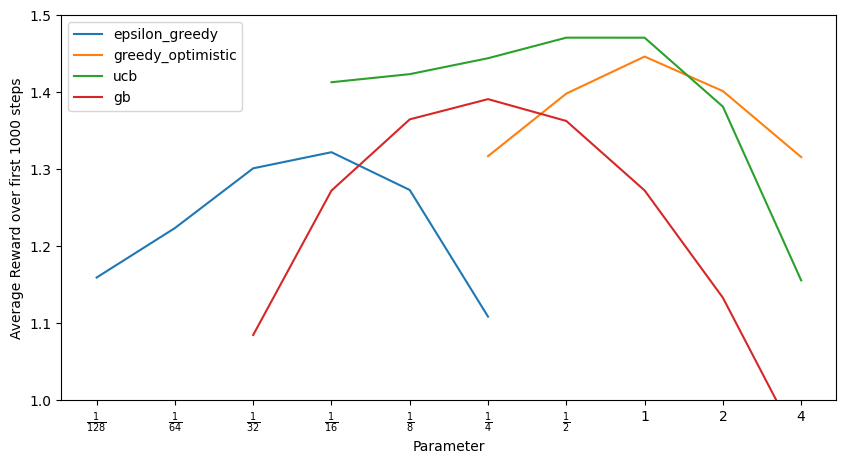

In [8]:
plt.figure(figsize=(10, 5))

for params in all_params:
    plt.plot(params["param_range"], results[params["method"]], label=params["method"])

plt.xscale('log', base=2)
plt.xticks(param_range,
           [r'$\frac{1}{128}$', r'$\frac{1}{64}$', r'$\frac{1}{32}$', 
            r'$\frac{1}{16}$', r'$\frac{1}{8}$', r'$\frac{1}{4}$', r'$\frac{1}{2}$', 
            r'$1$', r'$2$', r'$4$'])
plt.ylim(1, 1.5)

plt.xlabel("Parameter \n $\\epsilon, Q_0, c, \\alpha$")
plt.ylabel("Average Reward over first 1000 steps")
plt.legend()

plt.savefig("../images/figure_2_6.png", bbox_inches="tight")

## Non-stationary k-armed Bandit Testbed

In [9]:
# Bandit parameters
k = 10            # number of arms in the bandit
q_true_mean = 0.0
q_true_var = 0.0  # or should this be 1.0?
drift_var = 0.01

# Simulation parameters
T = 2_000  # number of timesteps played
R = 2000   # number of runs to play in the simulation

In [21]:
# Parameter range
param_range = [2**p for p in range(-7, 3)]

# Parameters
all_params = [
    # epsilon-greedy action-value method with Sample Average Estimator
    {
        "method": "epsilon_greedy",
        "params": {
            "estimator_class": SampleAverageEstimator,
            "agent_class": EpsilonGreedyAgent,   
        },
        "param_name": "epsilon",
        "param_range": param_range[0:6],
    },
    # epsilon-greedy action-value method with Constant Step-Size Estimator
    {
        "method": "epsilon_greedy_css",
        "params": {
            "estimator_class": ConstantStepSizeEstimator,
            "agent_class": EpsilonGreedyAgent,   
        },
        "param_name": "epsilon",
        "param_range": param_range[0:6],
    },
    # greedy agent with Constant Step-Size Estimator with optimistic initial values
    {
        "method": "greedy_optimistic",
        "params": {
            "estimator_class": ConstantStepSizeEstimator,
            "agent_class": EpsilonGreedyAgent,
            "epsilon": 0.0
        },
        "param_name": "initial_q",
        "param_range": param_range[5:],
    },
    # UCB agent with Sample Average Estimator
    {
        "method": "ucb",
        "params": {
            "estimator_class": SampleAverageEstimator,
            "agent_class": UCBAgent,
        },
        "param_name": "c",
        "param_range": param_range[3:],
    },
    # Gradient Bandit Agent
    {
        "method": "gb",
        "params": {
            "estimator_class": None,
            "agent_class": GradientBanditAgent,
        },
        "param_name": "alpha",
        "param_range": param_range[2:],
    }
]
results = defaultdict(list)

In [22]:
%%time

for params in all_params:
    for param_val in params["param_range"]:
        params["params"][params["param_name"]] = param_val
        # Average the average results over the last 1_000 steps
        results[params["method"]].append(
            run_experiment_parallel(
                R, T, k,
                q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
                **params["params"]
            )["average_rewards"][1_000:].mean()
        )

CPU times: user 56.6 s, sys: 8.39 s, total: 1min 5s
Wall time: 15min 14s


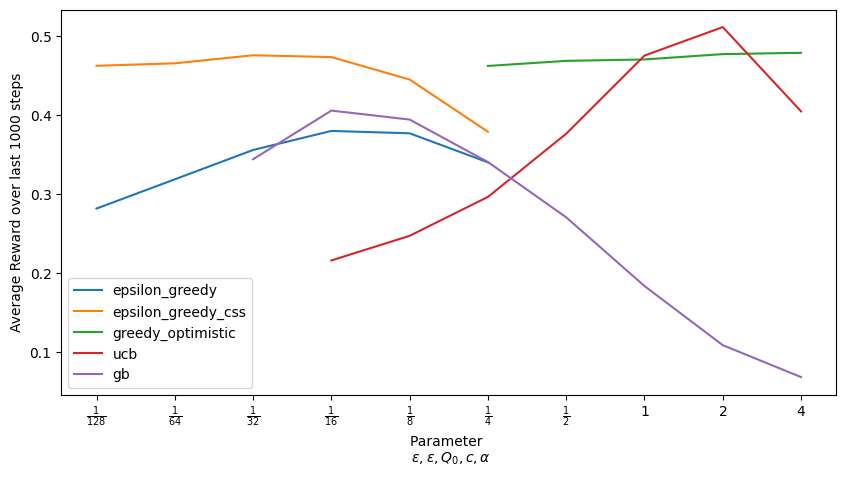

In [34]:
plt.figure(figsize=(10, 5))

for params in all_params:
    plt.plot(params["param_range"], results[params["method"]], label=params["method"])

plt.xscale('log', base=2)
plt.xticks(param_range,
           [r'$\frac{1}{128}$', r'$\frac{1}{64}$', r'$\frac{1}{32}$', 
            r'$\frac{1}{16}$', r'$\frac{1}{8}$', r'$\frac{1}{4}$', r'$\frac{1}{2}$', 
            r'$1$', r'$2$', r'$4$'])
# plt.ylim(1, 1.6)

plt.xlabel("Parameter \n $\\epsilon, \\epsilon, Q_0, c, \\alpha$")
plt.ylabel("Average Reward over last 1000 steps")
plt.legend()

plt.savefig("../images/figure_2_6_ns.png", bbox_inches="tight")